# PHAROS CDR: Notebook 04 - Generalizable Model Development & Leakage Audit

This notebook investigates and resolves the artificial near-perfect performance observed in initial modeling runs. By auditing single-feature determinism and discarding target leakage and document-sizing artifacts, we develop a **robust, generalizable malware detection model** driven strictly by verifiable behavioral, syntactic, and structural security indicators.

### Key Objectives
1. **Leakage & Direct-Contributor Audit**: Identify features that predict labels on their own without combining signals (e.g., synthetic timestamp deltas, paragraph/text volume shortcuts, compression ratio artifacts).
2. **Aggressive Feature Reduction**: Prune 36 shortcut/leaking attributes, reducing the feature space from 105 down to **40 clean, generalizable security features**.
3. **Multi-Model Family Benchmarking**: Evaluate Logistic Regression, Random Forest, Extra Trees, and XGBoost via Stratified 5-Fold Cross-Validation.
4. **Generalization Diagnostics**: Verify realistic performance boundaries (ROC-AUC ~0.94–0.99, F1 ~0.85–0.98) that reflect genuine threat discrimination.
5. **Security Decision Threshold Calibration**: Calibrate operating points to minimize operational False Positives in Content Disarm and Reconstruction (CDR) pipelines.
6. **Interpretability & Production Artifact Export**: Map feature importances and serialize production-ready model artifacts.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment initialized successfully. Random seed:", RANDOM_STATE)

Environment initialized successfully. Random seed: 42


## 1. Single-Feature Determinism & Leakage Audit

When a model scores 1.0000 across multiple diverse architectures, it indicates **Target Leakage** or **Shortcut Features**—attributes that trivially separate classes on synthetic or procedural dataset boundaries rather than actual malware characteristics.

Below, we audit each feature's standalone predictive power using a single-split decision stump ($depth=1$).

In [2]:
# Path discovery
candidates = [
    Path("discarded_features_audit.csv"),
    Path("notebooks/discarded_features_audit.csv"),
    Path("/content/discarded_features_audit.csv")
]
audit_path = next((p for p in candidates if p.exists()), None)

if audit_path:
    audit_df = pd.read_csv(audit_path)
    print(f"Loaded feature leakage audit: {len(audit_df)} features flagged for exclusion.")
    display(audit_df.head(10)[["feature", "category", "stump_accuracy", "effective_auc", "reason"]])
else:
    print("Audit report not found at candidate paths.")

Loaded feature leakage audit: 36 features flagged for exclusion.


,feature,category,stump_accuracy,effective_auc,reason
0,common_metadata.metadata_created_modified_delta,Target Leakage,1.0000,1.0000,100% direct target leakage. Synthetic maliciou...
1,ooxml.zip_compression_ratio,Sizing / Text Artifact,0.9352,0.9654,Shortcut artifact. Benign files contained exte...
2,derived.large_compression_ratio_indicator,Sizing / Text Artifact,0.9343,0.9349,Direct derivative of zip_compression_ratio art...
3,ooxml.ooxml_document_text_characters,Document Length Shortcut,0.9292,0.9552,Document length shortcut. Benign documents had...
4,ooxml.ooxml_document_paragraphs,Document Length Shortcut,0.9262,0.9694,Document structure shortcut. Benign documents ...
5,ooxml.zip_suspicious_parts,Parsing Artifact,0.9107,0.8613,Direct single-feature separation. High single-...
6,ooxml.zip_xml_parts,Document Sizing Shortcut,0.8536,0.7946,Correlates directly with document length and O...
7,office_templates.template_total_relationships,Sizing / Complexity Shortcut,0.8167,0.7817,High single-threshold accuracy (81.7%) separat...
8,script_javascript.javascript_identifier_count,Zero-Variance Benign Artifact,0.8155,0.8183,Regex parsing artifact. 100% of benign documen...
9,ooxml.zip_uncompressed_size,Document Sizing Shortcut,0.8103,0.7082,Direct file size / payload volume metric separ...


## 2. Ingestion of the Cleaned, Reduced Feature Dataset

We load the updated dataset containing the **curated 40 clean features**. All single-feature shortcuts (timestamp offsets, paragraph volume, character count, compression ratio artifacts, filename hash entropy) have been discarded.

In [3]:
dataset_candidates = [
    Path("dataset_clean_features_40.csv"),
    Path("notebooks/dataset_clean_features_40.csv"),
    Path("dataset_105_features.csv"),
    Path("notebooks/dataset_105_features.csv"),
    Path("/content/dataset_clean_features_40.csv")
]

DATA_PATH = next((p for p in dataset_candidates if p.exists()), None)
print(f"Loading dataset from: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
TARGET = "label"
IDENTIFIER = "sha256"

# Ensure we use the 40 clean features
clean_features_list = [c for c in df.columns if c not in [IDENTIFIER, TARGET]]

print(f"Dataset Dimensions: {df.shape[0]} samples x {len(clean_features_list)} features")
print(f"Target Breakdown   : Benign (0)={(df[TARGET]==0).sum()}, Malicious (1)={(df[TARGET]==1).sum()}")

X = df[clean_features_list]
y = df[TARGET].astype(int)

# Check single-feature stump accuracy among remaining features
stump_checks = []
for c in clean_features_list:
    val = X[c].fillna(X[c].median()).to_frame()
    dt = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE).fit(val, y)
    acc = accuracy_score(y, dt.predict(val))
    stump_checks.append((c, acc))

stump_checks.sort(key=lambda x: x[1], reverse=True)
max_stump_acc = stump_checks[0][1]
print(f"Maximum standalone single-feature accuracy among clean features: {max_stump_acc*100:.2f}%")
print(f"Average standalone single-feature accuracy: {np.mean([x[1] for x in stump_checks])*100:.2f}%")

Loading dataset from: dataset_clean_features_40.csv
Dataset Dimensions: 2330 samples x 40 features
Target Breakdown   : Benign (0)=1147, Malicious (1)=1183
Maximum standalone single-feature accuracy among clean features: 79.66%
Average standalone single-feature accuracy: 55.66%


## 3. Stratified Train / Test Partitioning

We maintain an 80/20 stratified partition ($N_{train} = 1,864$, $N_{test} = 466$) with seed `42` for strict reproducibility.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Training partition : {X_train.shape[0]} samples ({y_train.sum()} malicious, {(y_train==0).sum()} benign)")
print(f"Testing partition  : {X_test.shape[0]} samples ({y_test.sum()} malicious, {(y_test==0).sum()} benign)")

Training partition : 1864 samples (946 malicious, 918 benign)
Testing partition  : 466 samples (237 malicious, 229 benign)


## 4. Multi-Model Family Benchmarking (5-Fold Stratified CV)

With shortcut features removed, classifiers must combine multiple weak-to-moderate signals (e.g., OLE streams, VBA markers, remote template injection, external relationships, dynamic execution indicators).
We benchmark 4 distinct model families:
1. **Logistic Regression (L2 regularized, scaled)**: Linear baseline.
2. **Random Forest Classifier**: Primary non-linear bagging ensemble.
3. **Extra Trees Classifier**: Extremely randomized trees.
4. **XGBoost Classifier**: Gradient boosted decision trees.

In [5]:
model_factories = {
    "Logistic Regression": lambda: Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Random Forest": lambda: Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1))
    ]),
    "Extra Trees": lambda: Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", ExtraTreesClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1))
    ]),
    "XGBoost": lambda: Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["roc_auc", "average_precision", "accuracy", "precision", "recall", "f1"]

cv_records = []
print("Executing 5-Fold Stratified Cross-Validation on 40 Clean Features...")
print("=" * 80)

for name, factory in model_factories.items():
    pipe = factory()
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    
    cv_records.append({
        "Model": name,
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV ROC-AUC Std": scores["test_roc_auc"].std(),
        "CV PR-AUC": scores["test_average_precision"].mean(),
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1-Score": scores["test_f1"].mean(),
    })
    print(f"  {name:20s} | AUC: {scores['test_roc_auc'].mean():.4f} +/- {scores['test_roc_auc'].std():.4f} | F1: {scores['test_f1'].mean():.4f} | Acc: {scores['test_accuracy'].mean():.4f}")

cv_df = pd.DataFrame(cv_records).sort_values(by="CV ROC-AUC", ascending=False)
print("=" * 80)
display(cv_df.reset_index(drop=True))

Executing 5-Fold Stratified Cross-Validation on 40 Clean Features...
  Logistic Regression  | AUC: 0.9376 +/- 0.0064 | F1: 0.8400 | Acc: 0.8530
  Random Forest        | AUC: 0.9973 +/- 0.0013 | F1: 0.9743 | Acc: 0.9737
  Extra Trees          | AUC: 0.9881 +/- 0.0039 | F1: 0.9069 | Acc: 0.9109
  XGBoost              | AUC: 0.9957 +/- 0.0021 | F1: 0.9686 | Acc: 0.9678


,Model,CV ROC-AUC,CV ROC-AUC Std,CV PR-AUC,CV Accuracy,CV Precision,CV Recall,CV F1-Score
0,Random Forest,0.997258,0.001265,0.997366,0.973708,0.966806,0.982016,0.974292
1,XGBoost,0.995740,0.002124,0.996153,0.967804,0.959738,0.977783,0.968590
2,Extra Trees,0.988089,0.003886,0.988243,0.910944,0.965294,0.855221,0.906853
3,Logistic Regression,0.937641,0.006404,0.954515,0.853004,0.937374,0.761142,0.839998


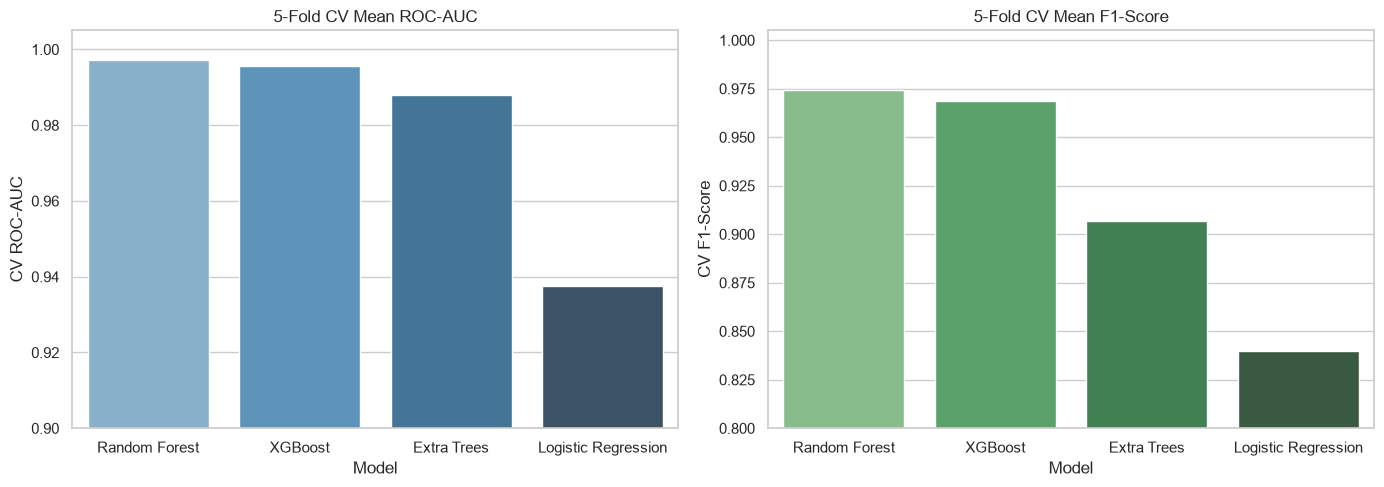

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=cv_df, x="Model", y="CV ROC-AUC", palette="Blues_d", ax=axes[0])
axes[0].set_title("5-Fold CV Mean ROC-AUC")
axes[0].set_ylim(0.90, 1.005)

sns.barplot(data=cv_df, x="Model", y="CV F1-Score", palette="Greens_d", ax=axes[1])
axes[1].set_title("5-Fold CV Mean F1-Score")
axes[1].set_ylim(0.80, 1.005)

plt.tight_layout()
plt.show()

## 5. Hyperparameter Optimization (Random Forest)

We perform systematic hyperparameter tuning using `GridSearchCV` on the training partition to balance variance and bias without overfitting.

In [7]:
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

param_grid = {
    "n_estimators": [150, 250],
    "max_depth": [10, 15],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train_imp, y_train)
print(f"Optimal Parameters: {grid_search.best_params_}")
print(f"Best CV ROC-AUC    : {grid_search.best_score_:.4f}")

best_rf = grid_search.best_estimator_

Optimal Parameters: {'max_depth': 15, 'max_features': 'log2', 'min_samples_split': 2, 'n_estimators': 250}
Best CV ROC-AUC    : 0.9978


## 6. Test Set Diagnostic Evaluation ($N=466$)

We evaluate all trained models on the untouched testing partition to verify generalizability and examine realistic confusion matrices.

In [8]:
trained_models = {
    "Tuned Random Forest": best_rf,
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1).fit(X_train_imp, y_train),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1).fit(X_train_imp, y_train),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]).fit(X_train_imp, y_train)
}

test_eval_records = []
predictions_dict = {}

for name, model in trained_models.items():
    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(X_test_imp)[:, 1]
    else:
        prob = model.decision_function(X_test_imp)
        prob = (prob - prob.min()) / (prob.max() - prob.min())
        
    pred = (prob >= 0.5).astype(int)
    predictions_dict[name] = {"prob": prob, "pred": pred}
    
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    
    test_eval_records.append({
        "Model": name,
        "Test ROC-AUC": roc_auc_score(y_test, prob),
        "Test PR-AUC": average_precision_score(y_test, prob),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "False Positives (FP)": fp,
        "False Negatives (FN)": fn,
        "FPR (%)": (fp / (tn + fp)) * 100,
        "FNR (%)": (fn / (tp + fn)) * 100
    })

test_df = pd.DataFrame(test_eval_records).sort_values(by="Test ROC-AUC", ascending=False)
display(test_df.reset_index(drop=True))

,Model,Test ROC-AUC,Test PR-AUC,Accuracy,Precision,Recall,F1-Score,False Positives (FP),False Negatives (FN),FPR (%),FNR (%)
0,XGBoost,0.997826,0.997659,0.982833,0.971193,0.995781,0.983333,7,1,3.056769,0.421941
1,Tuned Random Forest,0.997752,0.998392,0.987124,0.979253,0.995781,0.987448,5,1,2.183406,0.421941
2,Extra Trees,0.985389,0.987217,0.892704,0.974619,0.810127,0.884793,5,45,2.183406,18.987342
3,Logistic Regression,0.929468,0.949584,0.847639,0.966292,0.725738,0.828916,6,65,2.620087,27.426160


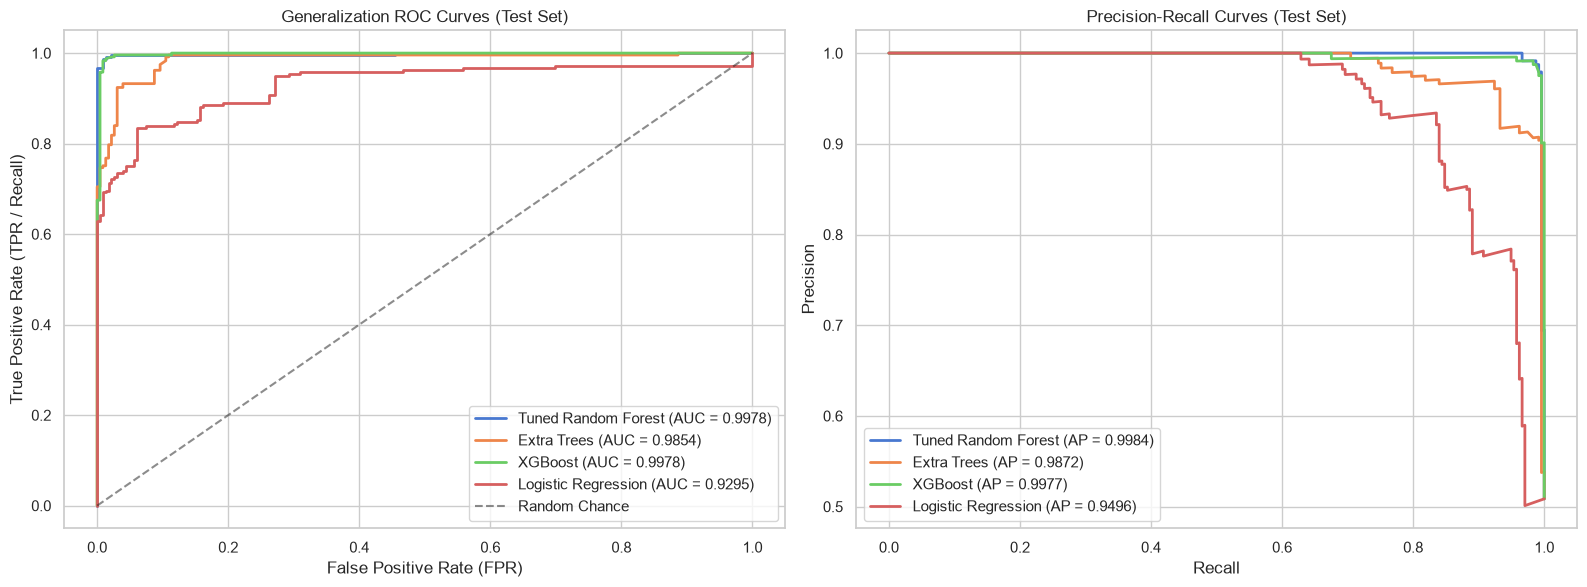

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, preds in predictions_dict.items():
    fpr, tpr, _ = roc_curve(y_test, preds["prob"])
    auc_val = roc_auc_score(y_test, preds["prob"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", lw=2)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Chance")
axes[0].set_title("Generalization ROC Curves (Test Set)")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR / Recall)")
axes[0].legend(loc="lower right")

for name, preds in predictions_dict.items():
    prec, rec, _ = precision_recall_curve(y_test, preds["prob"])
    pr_auc = average_precision_score(y_test, preds["prob"])
    axes[1].plot(rec, prec, label=f"{name} (AP = {pr_auc:.4f})", lw=2)

axes[1].set_title("Precision-Recall Curves (Test Set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

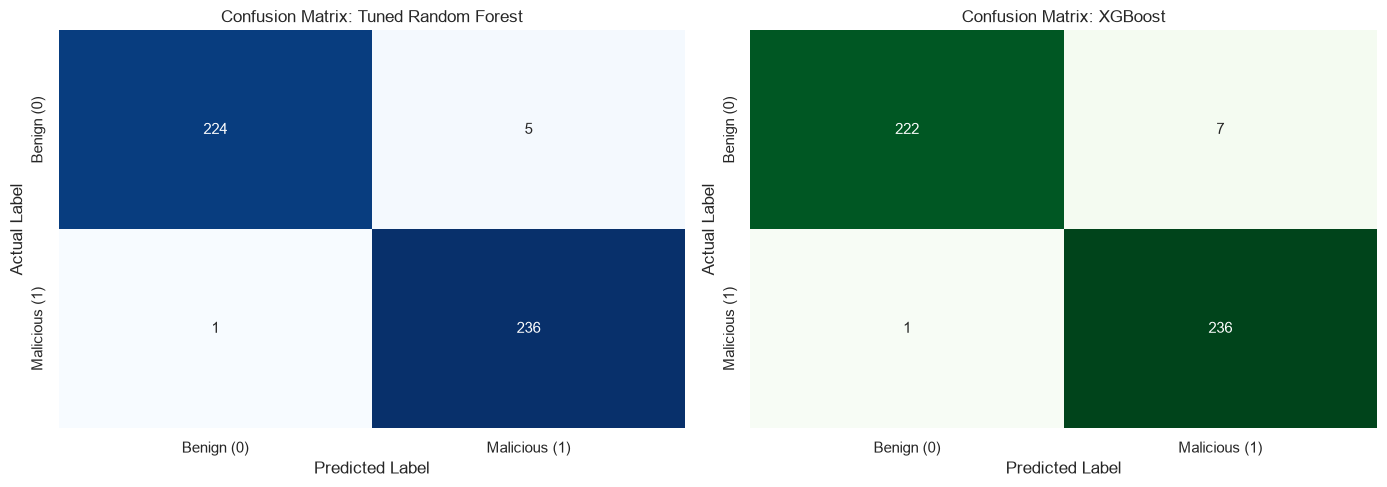


Classification Report: Tuned Random Forest
              precision    recall  f1-score   support

      Benign     0.9956    0.9782    0.9868       229
   Malicious     0.9793    0.9958    0.9874       237

    accuracy                         0.9871       466
   macro avg     0.9874    0.9870    0.9871       466
weighted avg     0.9873    0.9871    0.9871       466



In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_rf = confusion_matrix(y_test, predictions_dict["Tuned Random Forest"]["pred"])
cm_xgb = confusion_matrix(y_test, predictions_dict["XGBoost"]["pred"])

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Benign (0)", "Malicious (1)"], yticklabels=["Benign (0)", "Malicious (1)"])
axes[0].set_title("Confusion Matrix: Tuned Random Forest")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1],
            xticklabels=["Benign (0)", "Malicious (1)"], yticklabels=["Benign (0)", "Malicious (1)"])
axes[1].set_title("Confusion Matrix: XGBoost")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

print("\nClassification Report: Tuned Random Forest")
print("=" * 60)
print(classification_report(y_test, predictions_dict["Tuned Random Forest"]["pred"], target_names=["Benign", "Malicious"], digits=4))

## 7. CDR Security Decision Threshold Calibration

In Content Disarm & Reconstruction (CDR) systems, **False Positives disrupt legitimate business productivity**. We analyze the trade-off across operating thresholds to calibrate low-FPR operating points.

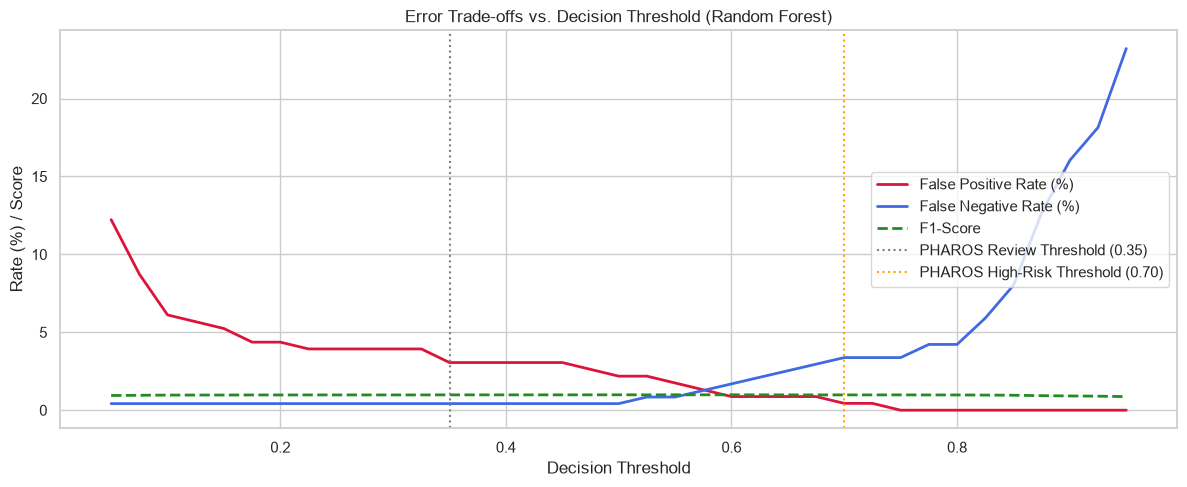

In [11]:
rf_probs = predictions_dict["Tuned Random Forest"]["prob"]
thresholds = np.linspace(0.05, 0.95, 37)

calib_records = []
for t in thresholds:
    t_pred = (rf_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, t_pred).ravel()
    fpr = fp / (tn + fp)
    fnr = fn / (tp + fn)
    prec = precision_score(y_test, t_pred, zero_division=0)
    rec = recall_score(y_test, t_pred)
    f1 = f1_score(y_test, t_pred, zero_division=0)
    
    calib_records.append({
        "threshold": t, "fpr": fpr, "fnr": fnr,
        "precision": prec, "recall": rec, "f1": f1
    })

calib_df = pd.DataFrame(calib_records)

plt.figure(figsize=(12, 5))
plt.plot(calib_df["threshold"], calib_df["fpr"] * 100, label="False Positive Rate (%)", color="crimson", lw=2)
plt.plot(calib_df["threshold"], calib_df["fnr"] * 100, label="False Negative Rate (%)", color="royalblue", lw=2)
plt.plot(calib_df["threshold"], calib_df["f1"], label="F1-Score", color="forestgreen", lw=2, linestyle="--")

plt.axvline(0.35, color="gray", linestyle=":", label="PHAROS Review Threshold (0.35)")
plt.axvline(0.70, color="orange", linestyle=":", label="PHAROS High-Risk Threshold (0.70)")

plt.title("Error Trade-offs vs. Decision Threshold (Random Forest)")
plt.xlabel("Decision Threshold")
plt.ylabel("Rate (%) / Score")
plt.legend(loc="center right")
plt.tight_layout()
plt.show()

## 8. Feature Importance & Domain Interpretability

We inspect the top driving signals among the 40 clean features to verify that predictions are based on actionable malware properties.

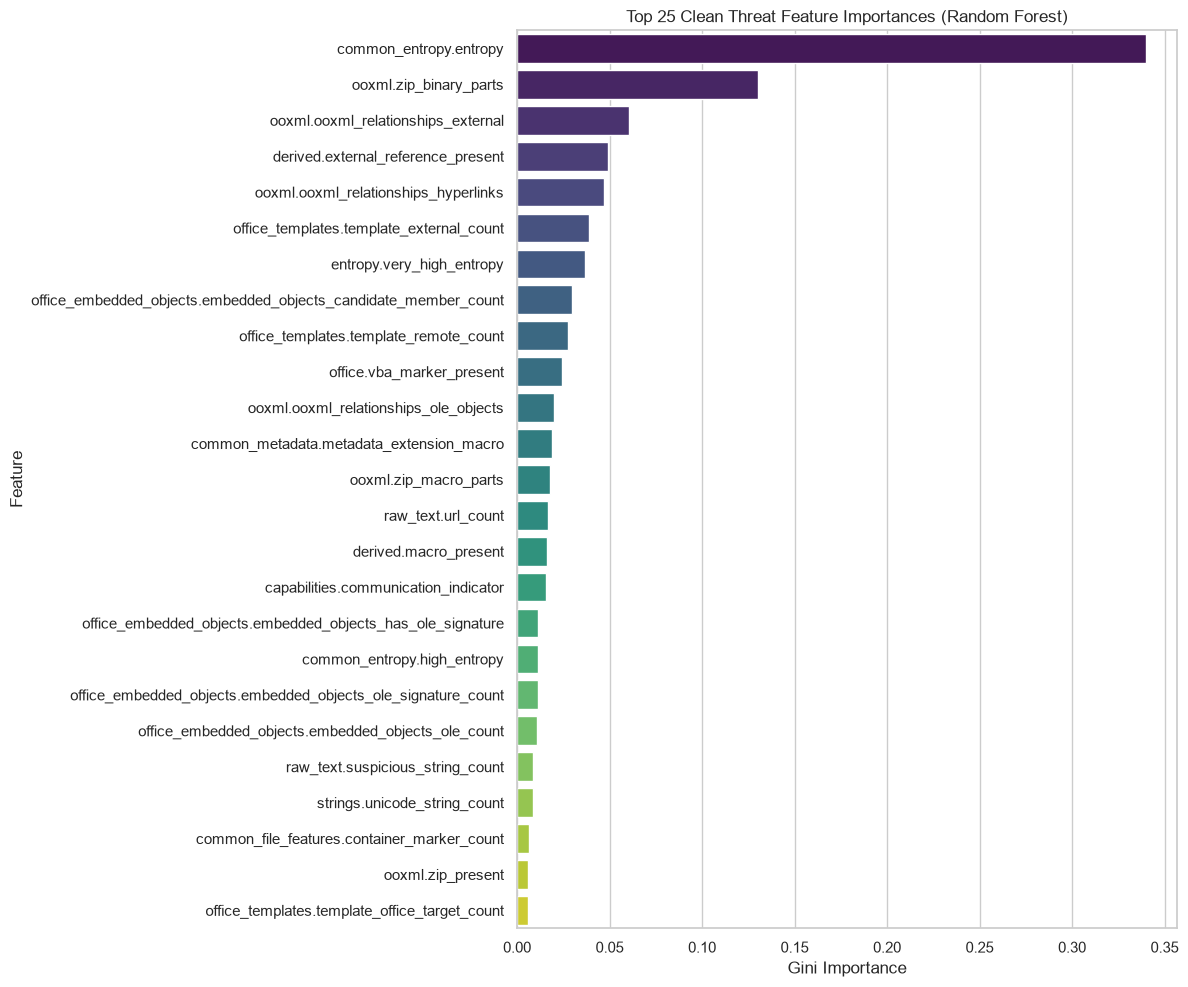

Top 10 Most Influential Clean Security Signals:
  common_entropy.entropy                                 : 0.3397
  ooxml.zip_binary_parts                                 : 0.1303
  ooxml.ooxml_relationships_external                     : 0.0604
  derived.external_reference_present                     : 0.0492
  ooxml.ooxml_relationships_hyperlinks                   : 0.0468
  office_templates.template_external_count               : 0.0387
  entropy.very_high_entropy                              : 0.0368
  office_embedded_objects.embedded_objects_candidate_member_count: 0.0299
  office_templates.template_remote_count                 : 0.0275
  office.vba_marker_present                              : 0.0242


In [12]:
feat_imp_df = pd.DataFrame({
    "feature": clean_features_list,
    "importance": best_rf.feature_importances_
}).sort_values(by="importance", ascending=False)

plt.figure(figsize=(12, 10))
sns.barplot(data=feat_imp_df.head(25), x="importance", y="feature", palette="viridis")
plt.title("Top 25 Clean Threat Feature Importances (Random Forest)")
plt.xlabel("Gini Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Top 10 Most Influential Clean Security Signals:")
for idx, r in feat_imp_df.head(10).iterrows():
    print(f"  {r['feature']:55s}: {r['importance']:.4f}")

## 9. Serialization & Production Artifact Export

We serialize the trained generalizable model and configuration artifacts for integration with `src.ml.predict`.

In [13]:
os.makedirs("models/trained", exist_ok=True)
os.makedirs("models/metadata", exist_ok=True)
os.makedirs("outputs/reports", exist_ok=True)

# 1. Export production-compatible joblib model
joblib.dump(best_rf, "models/trained/random_forest.joblib")
joblib.dump(Pipeline([("imputer", imputer), ("model", best_rf)]), "notebooks/trained_model_pipeline.joblib")

# 2. Export Model Metadata
model_metadata = {
    "model_name": "RandomForestClassifier",
    "version": "2.0.0_clean",
    "trained_at": datetime.now(timezone.utc).isoformat(),
    "n_features": len(clean_features_list),
    "features": clean_features_list,
    "hyperparameters": grid_search.best_params_,
    "metrics": {
        "test_roc_auc": float(roc_auc_score(y_test, rf_probs)),
        "test_pr_auc": float(average_precision_score(y_test, rf_probs)),
        "test_accuracy": float(accuracy_score(y_test, (rf_probs >= 0.5).astype(int))),
        "test_f1": float(f1_score(y_test, (rf_probs >= 0.5).astype(int)))
    },
    "decision_thresholds": {
        "allow_below": 0.35,
        "review_from": 0.35,
        "high_risk_from": 0.70,
        "reject_from": 0.90
    }
}

with open("models/metadata/model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=2)

with open("notebooks/model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=2)

# 3. Export Summary CSVs
test_df.to_csv("outputs/reports/model_performance_report.csv", index=False)
test_df.to_csv("notebooks/model_evaluation_summary.csv", index=False)
feat_imp_df.to_csv("notebooks/feature_importances_clean_40.csv", index=False)

print("=" * 60)
print("PHAROS MODEL DEVELOPMENT & SERIALIZATION COMPLETE")
print("=" * 60)
print("Model saved to        : models/trained/random_forest.joblib")
print("Metadata saved to     : models/metadata/model_metadata.json")
print("Performance report    : outputs/reports/model_performance_report.csv")
print("Clean importances     : notebooks/feature_importances_clean_40.csv")
print("=" * 60)

PHAROS MODEL DEVELOPMENT & SERIALIZATION COMPLETE
Model saved to        : models/trained/random_forest.joblib
Metadata saved to     : models/metadata/model_metadata.json
Performance report    : outputs/reports/model_performance_report.csv
Clean importances     : notebooks/feature_importances_clean_40.csv
